<a href="https://colab.research.google.com/github/BOUIDA-CHAIMA/Machine-Learning-samples/blob/main/TP09_KMeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP 9 — K-Means
**Machine Learning · Apprentissage non supervisé · Clustering**


| Exemple | Diapos | Problème |
|---|---|---|
| Exemple 1 | 66 – 67 | Répartir 4 clients en 2 groupes selon leurs visites par mois : 1, 2, 9 et 10 |

**Objectifs** : programmer **en Python pur** l’affectation au centre le plus proche, le recalcul des centres et le critère $J$ ; retrouver les itérations de la diapo ; comparer avec **scikit-learn** (`KMeans`).

## Rappel de cours

K-Means est **non supervisé** : il n’y a pas d’étiquette $y$. Il découvre lui-même des groupes.
1. **Choisir K** et placer K centres de départ (au hasard, ou avec *k-means++*).
2. **Affecter** chaque point au centre le plus proche : $c_i = \arg\min_k \|x_i - \mu_k\|^2$.
3. **Recalculer** chaque centre : $\mu_k$ = moyenne des points du groupe $k$.
4. **Répéter** 2 et 3 jusqu’à ce que les affectations ne changent plus.

Critère minimisé (`inertia_` dans scikit-learn) : $J = \sum_k \sum_{x \in C_k} \|x - \mu_k\|^2$. Il ne peut que baisser d’une itération à l’autre.

---
# Partie A — Implémentation from scratch (Python pur)

4 clients d’un magasin, nombre de visites par mois : **1, 2, 9 et 10**. On veut K = 2 groupes. Centres de départ choisis volontairement proches : $c_1 = 1$, $c_2 = 2$.

In [4]:
visites = [1, 2, 9, 10]
centres = [1.0, 2.0]

### Question 1 — Itération 1 : affecter chaque client au centre le plus proche
**Réponse.** $1 \to c_1$ (distance 0 < 1) ; $2 \to c_2$ (0 < 1) ; $9 \to c_2$ (7 < 8) ; $10 \to c_2$ (8 < 9). Groupes : G1 = {1}, G2 = {2, 9, 10}.

In [5]:
def affecter(points, centres):
    # Pour chaque point : indice du centre le plus proche
    return [min(range(len(centres)), key=lambda k: abs(x - centres[k])) for x in points]

def groupes(points, affectation, K):
    return [[x for x, a in zip(points, affectation) if a == k] for k in range(K)]

aff = affecter(visites, centres)
G = groupes(visites, aff, 2)
for x in visites:
    print(f"{x:>2} visites : distance à c1 = {abs(x - centres[0]):.0f}, à c2 = {abs(x - centres[1]):.0f} → G{affecter([x], centres)[0] + 1}")
assert G == [[1], [2, 9, 10]]
print("===== G1 = {1} ; G2 = {2, 9, 10}")

 1 visites : distance à c1 = 0, à c2 = 1 → G1
 2 visites : distance à c1 = 1, à c2 = 0 → G2
 9 visites : distance à c1 = 8, à c2 = 7 → G2
10 visites : distance à c1 = 9, à c2 = 8 → G2
===== G1 = {1} ; G2 = {2, 9, 10}


### Question 2 — Itération 1 : recalculer les centres
**Réponse.** $c_1 = 1/1 = 1$ ; $c_2 = (2 + 9 + 10)/3 = 7$.

In [6]:
def recalculer(G):
    return [sum(g) / len(g) for g in G]

centres = recalculer(G)
assert centres == [1.0, 7.0]
print(f"centres = {centres}")

centres = [1.0, 7.0]


### Question 3 — Recommencer jusqu’à stabilité
**Réponse.**
- Itération 2 : 2 est maintenant plus proche de $c_1$ ($|2-1| = 1 < |2-7| = 5$) → G1 = {1, 2}, G2 = {9, 10} → centres 1,5 et 9,5.
- Itération 3 : plus aucun changement → **convergence**.
- $J = 0{,}5^2 \times 4 = 1$.

In [7]:
def inertie(points, centres, affectation):
    return sum((x - centres[a]) ** 2 for x, a in zip(points, affectation))

def kmeans(points, centres, max_iter=100, afficher=True):
    centres = list(centres)
    historique = []
    for it in range(1, max_iter + 1):
        aff = affecter(points, centres)
        G = groupes(points, aff, len(centres))
        nouveaux = recalculer(G)
        historique.append((it, list(centres), G, nouveaux, inertie(points, nouveaux, affecter(points, nouveaux))))
        if afficher:
            print(f"Itération {it} : centres {centres} → groupes {G} → nouveaux centres {nouveaux} ; J = {historique[-1][4]}")
        if nouveaux == centres:
            break
        centres = nouveaux
    return centres, aff, historique

centres_finaux, aff_finale, hist = kmeans(visites, [1.0, 2.0])
assert hist[1][2] == [[1, 2], [9, 10]] and len(hist) == 3

print("Groupes : {1, 2} = « occasionnels » ; {9, 10} = « fidèles »")

Itération 1 : centres [1.0, 2.0] → groupes [[1], [2, 9, 10]] → nouveaux centres [1.0, 7.0] ; J = 14.0
Itération 2 : centres [1.0, 7.0] → groupes [[1, 2], [9, 10]] → nouveaux centres [1.5, 9.5] ; J = 1.0
Itération 3 : centres [1.5, 9.5] → groupes [[1, 2], [9, 10]] → nouveaux centres [1.5, 9.5] ; J = 1.0
Groupes : {1, 2} = « occasionnels » ; {9, 10} = « fidèles »


### Question 4 — Un nouveau client vient 8 fois par mois : quel groupe ?
**Réponse.** $|8 - 9{,}5| = 1{,}5 < |8 - 1{,}5| = 6{,}5$ → il rejoint le groupe G2, les **fidèles**.

In [8]:
d1, d2 = abs(8 - centres_finaux[0]), abs(8 - centres_finaux[1])
print(f"distance à c1 = {d1:.1f}, à c2 = {d2:.1f} → G{affecter([8], centres_finaux)[0] + 1}")
print("Client à 8 visites → G" + str(affecter([8], centres_finaux)[0] + 1), "(fidèles)")

distance à c1 = 6.5, à c2 = 1.5 → G2
Client à 8 visites → G2 (fidèles)


### Question 5 — Le résultat dépend du départ
**Réponse.** On teste plusieurs départs choisis parmi les 4 clients. Ici, les deux groupes sont très nets : tous les départs mènent à la même solution. Sur des données moins nettes, un mauvais départ peut bloquer K-Means dans une solution moins bonne (un $J$ plus grand). C’est pourquoi on relance plusieurs fois (`n_init`) et on garde le plus petit $J$.

In [ ]:
for depart in [(1, 2), (1, 9), (1, 10), (2, 9), (9, 10)]:
    c, a, _ = kmeans(visites, list(map(float, depart)), afficher=False)
    print(f"départ {depart} → centres {c} ; J = {inertie(visites, c, a)}")

départ (1, 2) → centres [1.5, 9.5] ; J = 1.0
départ (1, 9) → centres [1.5, 9.5] ; J = 1.0
départ (1, 10) → centres [1.5, 9.5] ; J = 1.0
départ (2, 9) → centres [1.5, 9.5] ; J = 1.0
départ (9, 10) → centres [1.5, 9.5] ; J = 1.0


---
# Partie B — Le même exemple avec scikit-learn

### Question 6 — `KMeans` avec les mêmes centres de départ, itération par itération
**Réponse.** On impose les centres de départ (`init=[[1], [2]]`, `n_init=1`) et on limite le nombre d’itérations (`max_iter`) pour voir chaque étape. Puis on utilise le réglage par défaut de la diapo 68 (`init="k-means++"`, `n_init=10`). À la fin, scikit-learn réaffecte les points aux derniers centres calculés : après une seule itération, il affiche donc déjà les groupes [0 0 1 1].

> **Rappel sur J.** Dans notre code comme dans scikit-learn, $J$ est calculé avec les nouveaux centres et la réaffectation des points : après l’itération 1, $J = 14$ (centres 1 et 7 ; 2 rejoint déjà le centre 1).

In [ ]:
import numpy as np
from sklearn.cluster import KMeans

Xv = np.array(visites, dtype=float).reshape(-1, 1)
for it in [1, 2, 3]:
    km = KMeans(n_clusters=2, init=np.array([[1.0], [2.0]]), n_init=1, max_iter=it, algorithm="lloyd", tol=0).fit(Xv)
    print(f"max_iter = {it} : centres = {km.cluster_centers_.ravel()} ; groupes = {km.labels_} ; J = {km.inertia_}")

km = KMeans(n_clusters=2, init="k-means++", n_init=10, random_state=42).fit(Xv)
print("\nk-means++ (n_init=10) : centres =", np.sort(km.cluster_centers_.ravel()), "; J =", km.inertia_)
groupe_8 = km.predict([[8]])[0]
print("Client à 8 visites → centre", km.cluster_centers_[groupe_8, 0])

max_iter = 1 : centres = [1. 7.] ; groupes = [0 0 1 1] ; J = 14.0
max_iter = 2 : centres = [1.5 9.5] ; groupes = [0 0 1 1] ; J = 1.0
max_iter = 3 : centres = [1.5 9.5] ; groupes = [0 0 1 1] ; J = 1.0

k-means++ (n_init=10) : centres = [1.5 9.5] ; J = 1.0
Client à 8 visites → centre 9.5


---
# Partie C — Comparaison et validation
### Question 7 — Les résultats concordent-ils ?

In [ ]:
import pandas as pd
km1 = KMeans(n_clusters=2, init=np.array([[1.0], [2.0]]), n_init=1, max_iter=1, algorithm="lloyd", tol=0).fit(Xv)
lignes = [
    ("Centres après itération 1", "1 et 7", f"{hist[0][3][0]:g} et {hist[0][3][1]:g}", " et ".join(f"{v:g}" for v in km1.cluster_centers_.ravel())),
    ("Centres finaux", "1,5 et 9,5", " et ".join(f"{v:g}" for v in centres_finaux), " et ".join(f"{v:g}" for v in np.sort(km.cluster_centers_.ravel()))),
    ("J final", 1, inertie(visites, centres_finaux, aff_finale), km.inertia_),
    ("Client à 8 visites → centre", 9.5, centres_finaux[affecter([8], centres_finaux)[0]], km.cluster_centers_[groupe_8, 0]),
]
display(pd.DataFrame(lignes, columns=["Grandeur", "Diapo", "Python pur", "scikit-learn"]))
assert np.allclose(km1.cluster_centers_.ravel(), hist[0][3])
assert np.allclose(np.sort(km.cluster_centers_.ravel()), centres_finaux) and np.isclose(km.inertia_, 1.0)
print("==== Python pur = scikit-learn (mêmes itérations, mêmes centres, même J)")

,Grandeur,Diapo,Python pur,scikit-learn
0,Centres après itération 1,1 et 7,1 et 7,1 et 7
1,Centres finaux,"1,5 et 9,5",1.5 et 9.5,1.5 et 9.5
2,J final,1,1.0,1.0
3,Client à 8 visites → centre,9.5,9.5,9.5


✅ Python pur = scikit-learn (mêmes itérations, mêmes centres, même J)


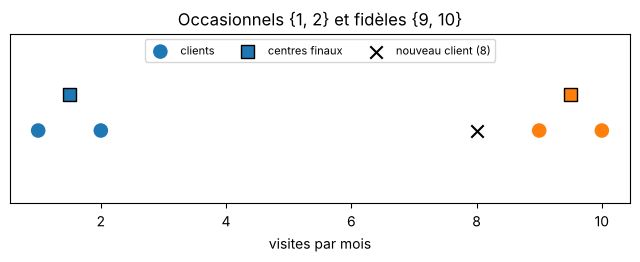

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 2.2))
couleurs = ["tab:blue", "tab:orange"]
ax.scatter(visites, [0] * 4, c=[couleurs[a] for a in aff_finale], s=90, zorder=3, label="clients")
ax.scatter(centres_finaux, [0.15] * 2, marker="s", c=couleurs, edgecolors="k", s=90, label="centres finaux")
ax.scatter([8], [0], marker="x", c="k", s=80, label="nouveau client (8)")
ax.set_yticks([]); ax.set_ylim(-0.3, 0.4); ax.set_xlabel("visites par mois"); ax.legend(fontsize=8, ncol=3, loc="upper center")
ax.set_title("Occasionnels {1, 2} et fidèles {9, 10}"); plt.show()

## Conclusion



**À retenir**
- K-Means n’a pas besoin d’étiquettes : il **découvre** des groupes.
- Ce qu’il apprend, ce sont les **K centres** ; ce que l’on choisit, c’est **K** et la façon de démarrer.
- Le résultat dépend du départ : on relance plusieurs fois (`n_init`) et on garde le plus petit $J$.